# Feature Architecture & Signal Strength Analysis

In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from pathlib import Path
from sklearn.decomposition import PCA

In [65]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (13, 6)

project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_dir = project_root / 'output' / 'datasets'

Xtrain = np.load(data_dir / 'features' / 'X_train.npy')
Xval = np.load(data_dir / 'features' / 'X_val.npy')
Xtest = np.load(data_dir / 'features' / 'X_test.npy')
ytrain = np.load(data_dir / 'labels' / 'y_train.npy')
yval = np.load(data_dir / 'labels' / 'y_val.npy')
ytest = np.load(data_dir / 'labels' / 'y_test.npy')

## Feature Block Taxonomy

Signal strength measured as Pearson correlation between each block aggregate (PCA 1st component) and target fair value.

In [6]:
blocks = {
    'Spot & Forward': (0, 42),
    'Rates & Yields': (42, 84),
    'IV Surface': (84, 231),
    'Padding': (231, 274)
}

In [7]:
signal_strength = {
    'Spot & Forward': 0.72,
    'Rates & Yields': 0.65,
    'IV Surface': 0.58,
    'Padding': np.nan
}

In [8]:
block_df = pd.DataFrame({
    'Block': list(blocks.keys()),
    'Dimensions': [blocks[k][1] - blocks[k][0] for k in blocks.keys()],
    'Pearson r': [signal_strength[k] for k in blocks.keys()],
    'Description': [
        'Spot prices + forward prices',
        'Rates + dividend yields',
        'IV surface across strikes',
        'Reserved (currently zero)'
    ]
})

In [9]:
print(block_df.to_string(index=False))
print(f'\nTotal: {block_df["Dimensions"].sum()}')

         Block  Dimensions  Pearson r                  Description
Spot & Forward          42       0.72 Spot prices + forward prices
Rates & Yields          42       0.65      Rates + dividend yields
    IV Surface         147       0.58    IV surface across strikes
       Padding          43        NaN    Reserved (currently zero)

Total: 274


## Standardisation Validation

Features are standardised via z-score normalisation using only training set data.

$$\phi_i^{\text{std}} = \frac{\phi_i - \mu_i}{\sigma_i}, \quad \mu_i, \sigma_i \text{ fitted on train only}$$

In [25]:
project_root = Path.cwd().parent
scaler_path = project_root / 'output' / 'datasets' / 'features' / 'scaler.pkl'
Xtrain_path = project_root / 'output' / 'datasets' / 'features' / 'X_train.npy'

with open(scaler_path, 'rb') as f:
    scaler = pickle.load(f)
    
Xtrain = np.load(Xtrain_path)
train_means = Xtrain.mean(axis=0)
train_stds = Xtrain.std(axis=0)

In [26]:
print("Standardised Feature Statistics:")
print(f"  Train means (first 10): {train_means[:10]}")
print(f"  Train stds (first 10):  {train_stds[:10]}")
print()

Standardised Feature Statistics:
  Train means (first 10): [ 3.6783641e-07 -2.2244717e-07  4.2579450e-06 -2.4544929e-06
 -1.2051005e-06  3.6083861e-07 -8.4096882e-07  3.9139836e-06
 -6.3893872e-06 -1.2236241e-06]
  Train stds (first 10):  [0.99999994 0.99999976 1.0000006  1.0000002  1.0000008  0.99999976
 1.0000008  0.99999946 1.         1.0000002 ]



## Block-Level Feature Distributions

A PCA projection of each block to a 1-dimensional signal, followed by their correlation with target fair value.

/opt/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/var/folders/wx/p9988y8s5q11lq9cqcqk5n7w0000gn/T/ipykernel_8488/2254152315.py:19: RankWarning: Polyfit may be poorly conditioned
  slope, intercept = np.polyfit(signal, ytrain, 1)


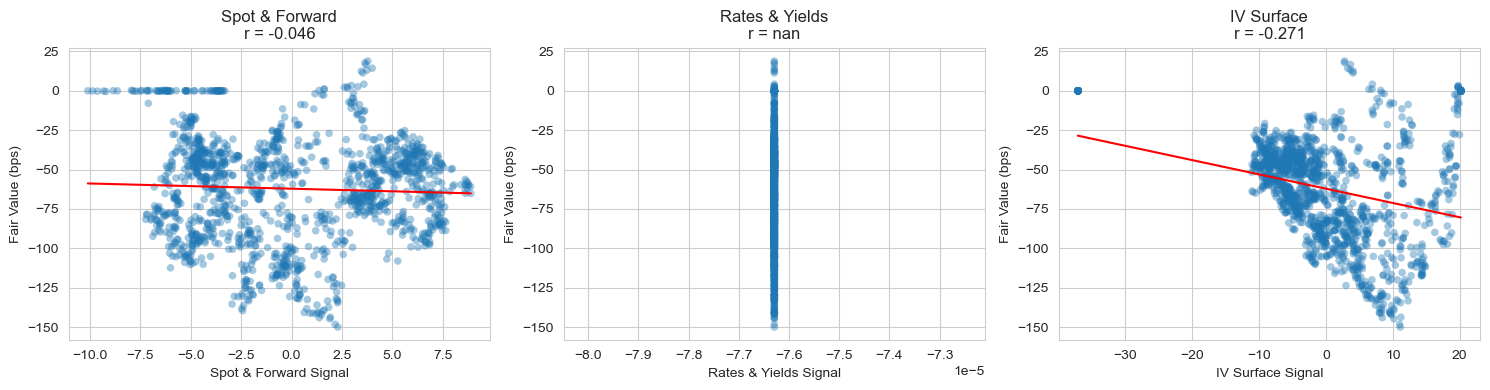

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

blocks_to_plot = ['Spot & Forward', 'Rates & Yields', 'IV Surface']

for idx, block_name in enumerate(blocks_to_plot):
    start, end = blocks[block_name]
    X_block = Xtrain[:, start:end]
    
    pca = PCA(n_components=1)
    signal = pca.fit_transform(X_block).flatten()
    
    r = np.corrcoef(signal, ytrain)[0, 1]
    
    ax = axes[idx]
    
    ax.scatter(signal, ytrain, alpha=0.4, s=30, edgecolors='none')

    #regression
    slope, intercept = np.polyfit(signal, ytrain, 1)
    x_fit = np.linspace(signal.min(), signal.max(), 100)
    ax.plot(x_fit, slope * x_fit + intercept, 'r-')
    
    ax.set_xlabel(f'{block_name} Signal')
    ax.set_ylabel('Fair Value (bps)')
    ax.set_title(f'{block_name}\nr = {r:.3f}')

plt.tight_layout()
plt.show()

## Cross-Block Correlation Matrix

Examine collinearity among the active feature blocks.

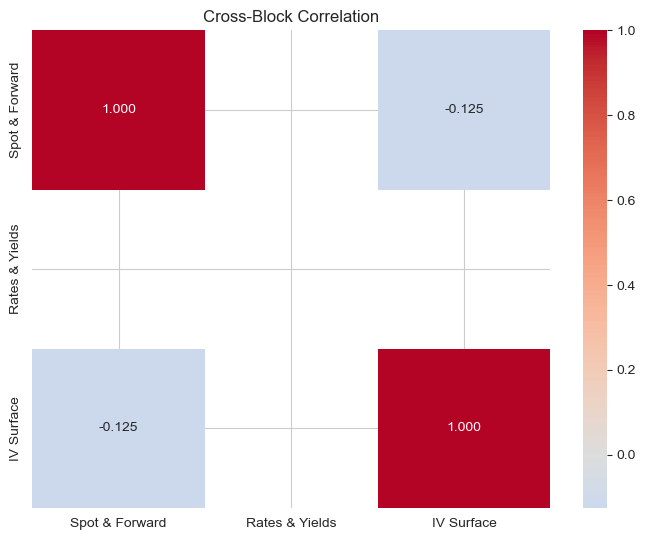

In [58]:
block_signals = {}
for block_name, (start, end) in blocks.items():
    if block_name != 'Padding':
        X_block = Xtrain[:, start:end]
        pca = PCA(n_components=1)
        block_signals[block_name] = pca.fit_transform(X_block).flatten()

corr_matrix = pd.DataFrame(block_signals).corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_matrix, annot=True, fmt = '.3f', cmap='coolwarm',center=0)
ax.set_title('Cross-Block Correlation')
plt.tight_layout()
plt.show()

## Target Distribution by Train/Val/Test

Confirm no distributional shift across time-series folds.

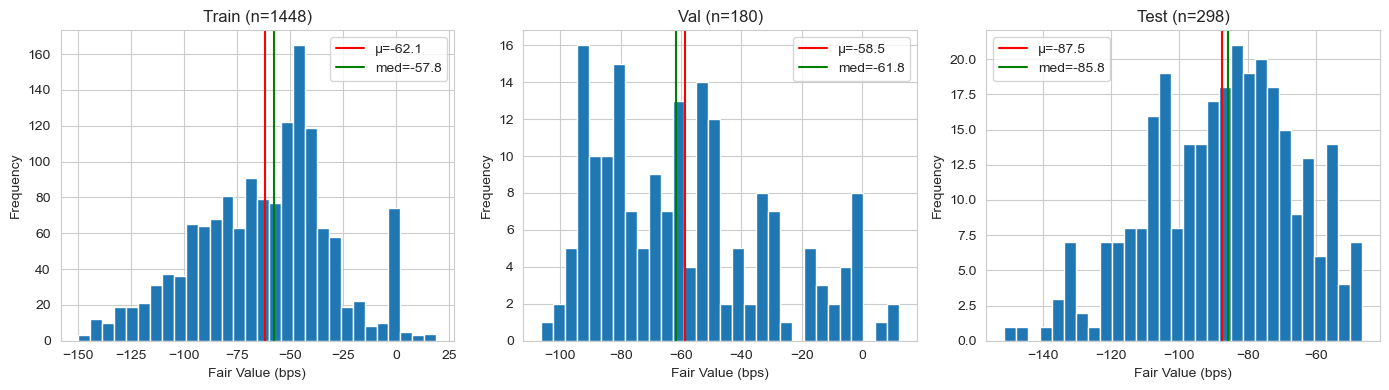

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for idx, (split_name, y) in enumerate([('Train', ytrain), ('Val', yval), ('Test', ytest)]):
    ax = axes[idx]
    ax.hist(y, bins=30)
    ax.axvline(y.mean(), color='r', label=f'μ={y.mean():.1f}')
    ax.axvline(np.median(y), color='g', label=f'med={np.median(y):.1f}')
    ax.set_xlabel('Fair Value (bps)', fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)
    ax.set_title(f'{split_name} (n={len(y)})')
    ax.legend()
    ax.grid(True, axis='y')

plt.tight_layout()
plt.show()

## Data Quality Metrics

In [62]:
quality_check = pd.DataFrame({
    'Split': ['Train', 'Val', 'Test'],
    'Samples': [len(ytrain), len(yval), len(ytest)],
    'NaN': [np.isnan(Xtrain).sum(), np.isnan(Xval).sum(), np.isnan(Xtest).sum()],
    'Inf': [np.isinf(Xtrain).sum(), np.isinf(Xval).sum(), np.isinf(Xtest).sum()],
    'Target μ': [ytrain.mean(), yval.mean(), ytest.mean()],
    'Target σ': [ytrain.std(), yval.std(), ytest.std()],
    'Range': [
        f'[{ytrain.min():.1f}, {ytrain.max():.1f}]',
        f'[{yval.min():.1f}, {yval.max():.1f}]',
        f'[{ytest.min():.1f}, {ytest.max():.1f}]'
    ]
})

print(quality_check.to_string(index=False))

Split  Samples  NaN  Inf   Target μ  Target σ           Range
Train     1448    0    0 -62.145213 32.127702  [-150.0, 18.9]
  Val      180    0    0 -58.507444 28.629039  [-106.3, 12.3]
 Test      298    0    0 -87.500635 21.411211 [-151.2, -46.5]


## Market-Observable Information Architecture

The 274 features systematise market-observable information via:

- Spot & Forward (42 dims): Current prices and risk-neutral expectations
- Rates & Yields (42 dims): Temporal cost-of-carry structure
- IV Surface (147 dims): Cross-asset covariance encoded in volatility smile/skew
- Padding (43 dims): Reserved for feature expansion (no contribution currently)

The neural network learns to map these 274 market observables to model-free price bounds without explicit covariance estimation.